In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

Load & Preprocess Data

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

CNN Model (3 different kernel sizes)

In [ ]:
model = models.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (5,5), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (7,7), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 717,258 (2.74 MB)

 Trainable params: 717,258 (2.74 MB)

 Non-trainable params: 0 (0.00 B)

Early Stopping + Checkpoint

In [ ]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    'best_model.keras',
    monitor='val_accuracy',
    save_best_only=True
)

Train Model

In [ ]:
history = model.fit(
    x_train, y_train,
    epochs=100,
    batch_size=512,
    validation_split=0.2,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.2922 - loss: 1.9269 - val_accuracy: 0.3755 - val_loss: 1.7827
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4437 - loss: 1.5327 - val_accuracy: 0.5009 - val_loss: 1.3868
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5095 - loss: 1.3602 - val_accuracy: 0.5597 - val_loss: 1.2353
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.5696 - loss: 1.2116 - val_accuracy: 0.5386 - val_loss: 1.2971
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5969 - loss: 1.1369 - val_accuracy: 0.6030 - val_loss: 1.1307
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6395 - loss: 1.0216 - val_accuracy: 0.6143 - val_loss: 1.0879
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6683 - loss: 0.9521 - val_accuracy: 0.6431 - val_loss: 0.9895
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6884 - loss: 0.8866 - val_accuracy: 

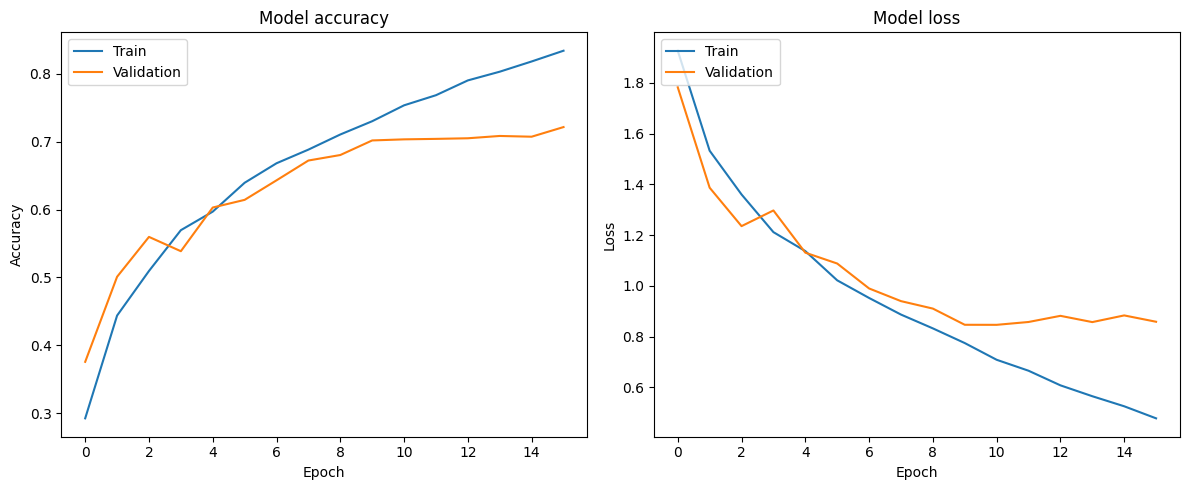

In [ ]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

**FGSM Attack**

In [ ]:
loss_object = tf.keras.losses.CategoricalCrossentropy()

def fgsm_attack(model, images, labels, epsilon):
    images = tf.convert_to_tensor(images)
    labels = tf.convert_to_tensor(labels)

    with tf.GradientTape() as tape:
        tape.watch(images)
        predictions = model(images)
        loss = loss_object(labels, predictions)

    gradient = tape.gradient(loss, images)
    signed_grad = tf.sign(gradient)

    adv_images = images + epsilon * signed_grad
    adv_images = tf.clip_by_value(adv_images, 0, 1)

    return adv_images

**BIM Attack**

In [ ]:
def bim_attack(model, images, labels, epsilon=0.03, alpha=0.005, iterations=10):
    adv_images = images

    for i in range(iterations):
        adv_images = fgsm_attack(model, adv_images, labels, alpha)
        adv_images = tf.clip_by_value(adv_images, images - epsilon, images + epsilon)
        adv_images = tf.clip_by_value(adv_images, 0, 1)

    return adv_images

**PGD Attack**

In [ ]:
def pgd_attack(model, images, labels, epsilon=0.03, alpha=0.005, iterations=20):
    adv_images = images + tf.random.uniform(images.shape, -epsilon, epsilon)
    adv_images = tf.clip_by_value(adv_images, 0, 1)

    for i in range(iterations):
        adv_images = fgsm_attack(model, adv_images, labels, alpha)
        adv_images = tf.clip_by_value(adv_images, images - epsilon, images + epsilon)
        adv_images = tf.clip_by_value(adv_images, 0, 1)

    return adv_images

Evaluation Function

In [ ]:
def evaluate_model(model, x, y, name="Dataset"):
    loss, acc = model.evaluate(x, y, verbose=0)
    print(f"{name} Accuracy: {acc:.4f}, Loss: {loss:.4f}")

    y_pred = model.predict(x)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y, axis=1)

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred_classes))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred_classes)
    plt.figure(figsize=(8, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix for {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

Evaluate All Cases

Clean Accuracy: 0.6990, Loss: 0.8538
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.74      0.73      1000
           1       0.84      0.77      0.80      1000
           2       0.56      0.64      0.60      1000
           3       0.49      0.59      0.54      1000
           4       0.65      0.64      0.65      1000
           5       0.65      0.55      0.60      1000
           6       0.81      0.75      0.78      1000
           7       0.84      0.67      0.75      1000
           8       0.74      0.88      0.80      1000
           9       0.78      0.76      0.77      1000

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000


Confusion Matrix:


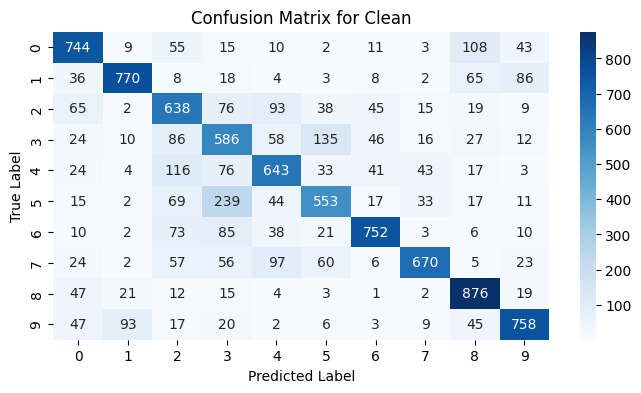

In [ ]:
# Clean
evaluate_model(model, x_test, y_test, "Clean")

FGSM Accuracy: 0.0635, Loss: 4.3907
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.11      0.12      0.11      1000
           1       0.09      0.06      0.07      1000
           2       0.03      0.04      0.03      1000
           3       0.01      0.01      0.01      1000
           4       0.01      0.02      0.01      1000
           5       0.05      0.04      0.04      1000
           6       0.06      0.05      0.05      1000
           7       0.10      0.05      0.07      1000
           8       0.15      0.20      0.17      1000
           9       0.06      0.06      0.06      1000

    accuracy                           0.06     10000
   macro avg       0.07      0.06      0.06     10000
weighted avg       0.07      0.06      0.06     10000


Confusion Matrix:


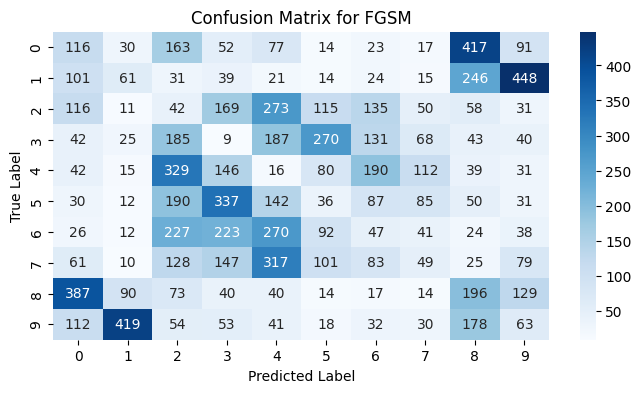

In [ ]:
# FGSM
x_fgsm = fgsm_attack(model, x_test, y_test, epsilon=0.03)
evaluate_model(model, x_fgsm, y_test, "FGSM")

BIM Accuracy: 0.0133, Loss: 6.6880
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.03      0.03      0.03      1000
           1       0.02      0.02      0.02      1000
           2       0.01      0.01      0.01      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.01      0.01      0.01      1000
           6       0.01      0.01      0.01      1000
           7       0.02      0.01      0.02      1000
           8       0.03      0.04      0.04      1000
           9       0.01      0.01      0.01      1000

    accuracy                           0.01     10000
   macro avg       0.01      0.01      0.01     10000
weighted avg       0.01      0.01      0.01     10000


Confusion Matrix:


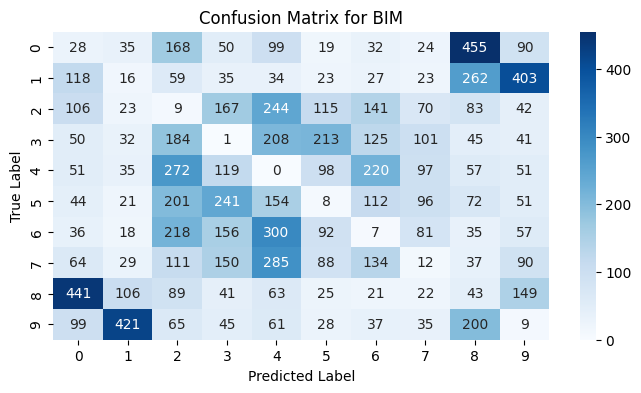

In [ ]:
# BIM
x_bim = bim_attack(model, x_test, y_test)
evaluate_model(model, x_bim, y_test, "BIM")

PGD Accuracy: 0.0099, Loss: 7.0568
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.02      0.02      0.02      1000
           1       0.02      0.01      0.01      1000
           2       0.00      0.01      0.01      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.01      0.01      0.01      1000
           6       0.00      0.00      0.00      1000
           7       0.02      0.01      0.01      1000
           8       0.03      0.03      0.03      1000
           9       0.01      0.01      0.01      1000

    accuracy                           0.01     10000
   macro avg       0.01      0.01      0.01     10000
weighted avg       0.01      0.01      0.01     10000


Confusion Matrix:


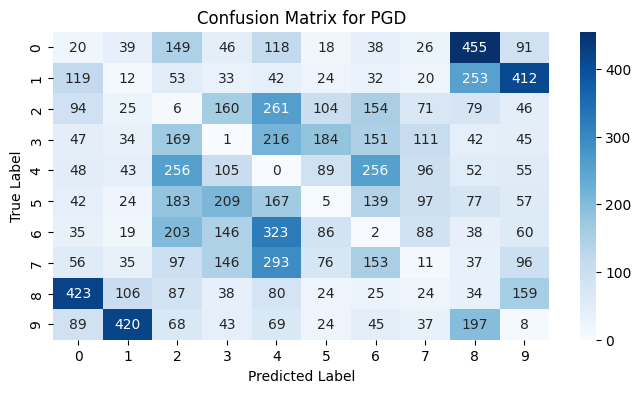

In [ ]:
# PGD
x_pgd = pgd_attack(model, x_test, y_test)
evaluate_model(model, x_pgd, y_test, "PGD")

Visualisation

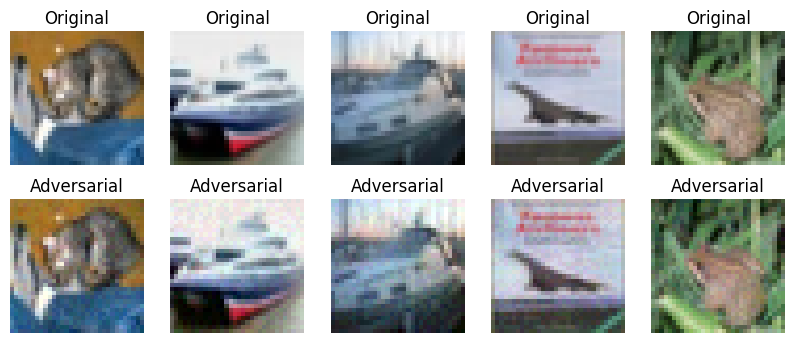

In [ ]:
def show_images(original, adversarial):
    plt.figure(figsize=(10,4))

    for i in range(5):
        # Original
        plt.subplot(2,5,i+1)
        plt.imshow(original[i])
        plt.title("Original")
        plt.axis('off')

        # Adversarial
        plt.subplot(2,5,i+6)
        plt.imshow(adversarial[i])
        plt.title("Adversarial")
        plt.axis('off')

    plt.show()

# Example
show_images(x_test, x_fgsm.numpy())

In [ ]:
results = []

# Clean
loss, acc_clean = model.evaluate(x_test, y_test, verbose=0)
results.append(["Clean", "-", acc_clean])

# FGSM
epsilon = 0.03
x_fgsm = fgsm_attack(model, x_test, y_test, epsilon)
_, acc_fgsm = model.evaluate(x_fgsm, y_test, verbose=0)
results.append(["FGSM", epsilon, acc_fgsm])

# BIM
x_bim = bim_attack(model, x_test, y_test)
_, acc_bim = model.evaluate(x_bim, y_test, verbose=0)
results.append(["BIM", 0.03, acc_bim])

# PGD
x_pgd = pgd_attack(model, x_test, y_test)
_, acc_pgd = model.evaluate(x_pgd, y_test, verbose=0)
results.append(["PGD", 0.03, acc_pgd])

In [ ]:
import pandas as pd

df = pd.DataFrame(results, columns=["Attack", "Epsilon", "Test Accuracy"])
print(df)

  Attack Epsilon  Test Accuracy
0  Clean       -         0.6990
1   FGSM    0.03         0.0635
2    BIM    0.03         0.0133
3    PGD    0.03         0.0101
